In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/simple_login_activity1')

df.head()

print(df.info)

<bound method DataFrame.info of      record_id  failed_logins  login_hour  new_device  download_mb       label
0            1            4.0           1           0        164.9  Suspicious
1            2            3.0           3           1        250.6  Suspicious
2            3            3.0          10           0        145.1      Normal
3            4            2.0          11           0        397.8      Normal
4            5            1.0           3           0        409.3      Normal
..         ...            ...         ...         ...          ...         ...
96          97            1.0          22           0        544.1      Normal
97          98            7.0          19           1        137.6  Suspicious
98          99            3.0          12           0        149.2      Normal
99         100            2.0          11           1        164.8      Normal
100          9            1.0           8           0        400.0  Suspicious

[101 rows x 6 colum

In [2]:
print("missing values begore cleaning")
df.isna().sum()


missing values begore cleaning


,0
record_id,0
failed_logins,1
login_hour,0
new_device,0
download_mb,1
label,0


In [3]:
print("duplicated rows:", df.duplicated().sum())

duplicated rows: 1


In [4]:
df = df.drop_duplicates().copy()
df["failed_logins"] = df['failed_logins'].fillna(df['failed_logins'].median())

In [5]:
print(df.head(25))

    record_id  failed_logins  login_hour  new_device  download_mb       label
0           1            4.0           1           0        164.9  Suspicious
1           2            3.0           3           1        250.6  Suspicious
2           3            3.0          10           0        145.1      Normal
3           4            2.0          11           0        397.8      Normal
4           5            1.0           3           0        409.3      Normal
5           6            6.0          10           0          NaN  Suspicious
6           7            1.0          14           0        651.7      Normal
7           8            0.0           5           1        202.2      Normal
8           9            1.0           8           0        400.0  Suspicious
9          10            3.0           8           0        245.5      Normal
10         11            1.0          12           1        242.2      Normal
11         12            1.0           8           1         39.

In [6]:
print("Missing values after cleaning:", df.isna().sum().sum())
print("Duplicate rows after cleaning:",df.duplicated().sum())
print('final rows :', len(df))

Missing values after cleaning: 1
Duplicate rows after cleaning: 0
final rows : 100


In [7]:
from sklearn.model_selection import train_test_split

features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'download_mb'
]

X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 75
Testing rows: 25


Accuracy: 88.00%


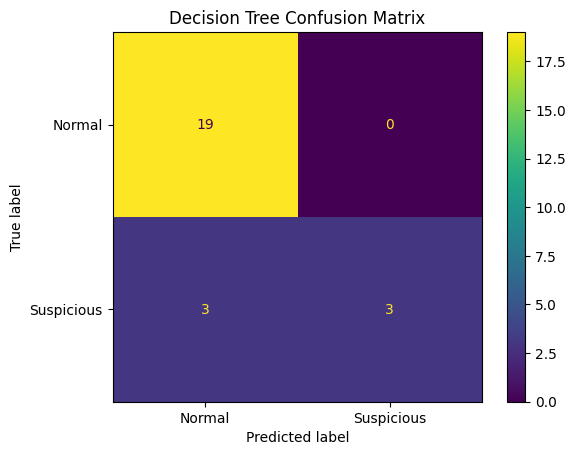

In [8]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay
)

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy: {accuracy * 100:.2f}%')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['Normal', 'Suspicious']
)

plt.title('Decision Tree Confusion Matrix')
plt.show()

In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select only numerical features
features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'download_mb'
]

X = df[features].copy()

# Make sure all features are numeric
X = X.apply(pd.to_numeric, errors='coerce')

# Remove rows containing missing values
X = X.dropna()

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create K-Means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Create clusters
df.loc[X.index, 'cluster'] = kmeans.fit_predict(X_scaled)

# Cluster summary
cluster_summary = df.loc[X.index].groupby('cluster')[features].mean().round(2)

# Compare clusters with actual labels
label_summary = pd.crosstab(
    df.loc[X.index, 'cluster'],
    df.loc[X.index, 'label']
)

display(cluster_summary)
display(label_summary)

,failed_logins,login_hour,new_device,download_mb
cluster,,,,
0.0,2.1,11.66,0.0,237.00
1.0,2.0,12.81,1.0,192.69


label,Normal,Suspicious
cluster,,
0.0,51,11
1.0,24,13


,feature,importance
1,login_hour,0.413391
0,failed_logins,0.392826
3,download_mb,0.193783
2,new_device,0.000000


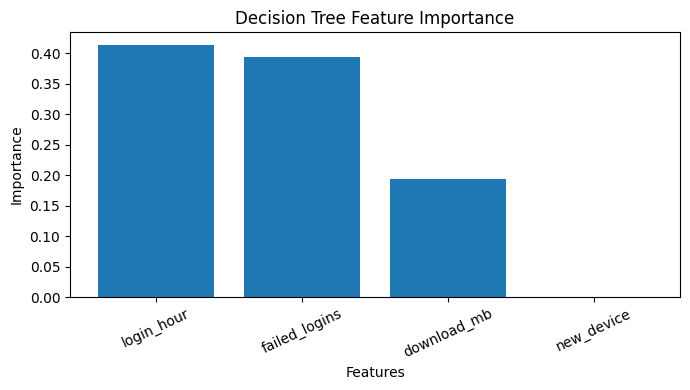

,failed_logins,login_hour,new_device,download_mb,prediction
0,0,10,0,45,Normal
1,8,2,1,180,Suspicious
2,2,23,1,900,Suspicious


In [10]:
# Feature Importance
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values(
    'importance',
    ascending=False
)

display(importance)


# Feature Importance Graph
plt.figure(figsize=(7, 4))

plt.bar(
    importance['feature'],
    importance['importance']
)

plt.title('Decision Tree Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()


# New Login Records
new_records = pd.DataFrame([
    {
        'failed_logins': 0,
        'login_hour': 10,
        'new_device': 0,
        'download_mb': 45
    },
    {
        'failed_logins': 8,
        'login_hour': 2,
        'new_device': 1,
        'download_mb': 180
    },
    {
        'failed_logins': 2,
        'login_hour': 23,
        'new_device': 1,
        'download_mb': 900
    }
])


# Predict Normal / Suspicious
new_records['prediction'] = model.predict(
    new_records[features]
)


# Display Predictions
display(new_records)

In [11]:
# False Positive and False Negative Examples

print(
    'False positive example:',
    'Legitimate late-night work on a new device is marked Suspicious.'
)

print(
    'False negative example:',
    'A disguised attack with few obvious indicators is marked Normal.'
)


# Save the complete results
df.to_csv('Lab2_Login_ML_Result.csv', index=False)

print('Saved: Lab2_Login_ML_Result.csv')

False positive example: Legitimate late-night work on a new device is marked Suspicious.
False negative example: A disguised attack with few obvious indicators is marked Normal.
Saved: Lab2_Login_ML_Result.csv
